# 20. Riemannian Geometry

This notebook follows Section 4.4, **Riemannian Geometry**, of Bronstein, Bruna, Cohen, and Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges* (the proto-book), through page 51. It stops before **Fourier Analysis on Manifolds**, which will be treated separately.

Borde and Bronstein's *Mathematical Foundations of Geometric Deep Learning* provides complementary context. Loring W. Tu's *Differential Geometry: Connections, Curvature, and Characteristic Classes* is a supplementary reference.

## Learning goals

- Define a Riemannian metric and understand its role on each tangent space.
- Define lengths, geodesics, the exponential map, and geodesic distance.
- State the Hopf–Rinow theorem and the Nash embedding theorem.
- Distinguish intrinsic geometry from the choice of an ambient embedding.
- Explain why these ideas matter for geometric deep learning (GDL).

## 1. From a manifold to a Riemannian manifold

A smooth manifold is locally modeled on Euclidean space, but its smooth structure alone does not specify lengths or angles. A **Riemannian metric** supplies this information by assigning an inner product to each tangent space, varying smoothly from point to point.

### Definition

A Riemannian metric on $\mathcal M$ is a smooth family of maps

$$
g_p:T_p\mathcal M\times T_p\mathcal M\to\mathbb R
$$

such that each $g_p$ is bilinear, symmetric, and positive definite:

$$
g_p(X,Y)=g_p(Y,X),\qquad g_p(X,X)>0\quad(X\ne0).
$$

The pair $(\mathcal M,g)$ is a **Riemannian manifold**.

### Coordinate expression

For local coordinates $(x^1,\ldots,x^n)$, let $\partial_i=\frac{\partial}{\partial x^i}$. Define

$$
g_{ij}(x)=g(\partial_i,\partial_j),\qquad G(x)=(g_{ij}(x)).
$$

If $X=X^i\partial_i$ and $Y=Y^j\partial_j$, then

$$
g(X,Y)=\sum_{i,j=1}^n g_{ij}(x)X^iY^j=X^\mathsf T G(x)Y.
$$

The matrix $G(x)$ is symmetric and positive definite. Coordinates of vectors depend on the chart, but the metric pairing is geometric.

### Example: Euclidean space

On $\mathbb R^n$, the standard metric is

$$
g_x(X,Y)=X^\mathsf T Y=\sum_i X^iY^i,
$$

so $G(x)=I_n$.

### Example: the sphere

The unit sphere is $S^2=\{p\in\mathbb R^3:p^\mathsf Tp=1\}$. Its tangent space is

$$
T_pS^2=\{X\in\mathbb R^3:p^\mathsf TX=0\}.
$$

The standard spherical metric is the Euclidean inner product restricted to tangent vectors:

$$
g_p(X,Y)=X^\mathsf TY,\qquad X,Y\in T_pS^2.
$$

Each tangent space is a vector plane, while the sphere itself is globally curved. The tangent plane approximates the sphere locally; it is not the sphere.

## 2. Norms and curve lengths

A metric defines the norm of a tangent vector $X\in T_p\mathcal M$:

$$
\|X\|_g=\sqrt{g_p(X,X)}.
$$

For a piecewise-smooth curve $\gamma:[a,b]\to\mathcal M$, its velocity $\dot\gamma(t)$ lies in $T_{\gamma(t)}\mathcal M$. The Riemannian length is

$$
L_g(\gamma)=\int_a^b
\sqrt{g_{\gamma(t)}(\dot\gamma(t),\dot\gamma(t))}\,dt.
$$

In coordinates $x^i(t)$,

$$
L_g(\gamma)=\int_a^b
\sqrt{\sum_{i,j}g_{ij}(x(t))\dot x^i(t)\dot x^j(t)}\,dt.
$$

This generalizes the arc-length formula from multivariable calculus: the metric converts coordinate velocity into geometric speed.

A related functional is the energy,

$$
E(\gamma)=\frac12\int_a^b
g_{\gamma(t)}(\dot\gamma(t),\dot\gamma(t))\,dt.
$$

Geodesics can be characterized variationally as critical curves of energy under suitable fixed-endpoint conditions. For constant-speed curves, length and energy are closely related.

## Scalar and Vector Fields

Let $(\mathcal{M},g)$ be a Riemannian manifold of dimension $n$.

### Scalar fields

A **scalar field** on $\mathcal{M}$ is a smooth function

$$
x:\mathcal{M}\longrightarrow\mathbb{R}.
$$

It assigns a real number $x(u)$ to every point $u\in\mathcal{M}$. The space of smooth scalar fields is denoted by $C^\infty(\mathcal{M})$.

Examples include temperature on the surface of the Earth, elevation on a terrain, and a real-valued signal defined on a curved surface.

The Riemannian metric induces a volume element $dV_g$. We can therefore define an inner product on suitable scalar fields by

$$
\langle x,y\rangle_{L^2(\mathcal{M})}
=
\int_{\mathcal{M}}x(u)y(u)\,dV_g(u).
$$

The volume element is important: it allows us to integrate functions over a manifold without relying on an arbitrary coordinate representation.

### Tangent vector fields

The tangent space $T_u\mathcal{M}$ contains the possible infinitesimal directions of motion at a point $u$. Since tangent spaces at different points need not coincide, a vector field must assign a vector from the appropriate tangent space to each point.

A **smooth tangent vector field** is a smooth map

$$
X:\mathcal{M}\longrightarrow T\mathcal{M},
\qquad
u\longmapsto X(u)\in T_u\mathcal{M},
$$

where $T\mathcal{M}$ denotes the tangent bundle of $\mathcal{M}$.

For example, a velocity field describing fluid motion on a spherical surface assigns a tangent velocity vector to each point of the sphere.

The Riemannian metric defines an inner product between vector fields:

$$
\langle X,Y\rangle_{L^2(T\mathcal{M})}
=
\int_{\mathcal{M}}
g_u\bigl(X(u),Y(u)\bigr)\,dV_g(u).
$$

Here $g_u$ is the inner product on the tangent space $T_u\mathcal{M}$. Thus, the inner product is computed pointwise and then integrated over the manifold.

### Scalar fields versus vector fields

The distinction is fundamental:

- A scalar field assigns a number to each point.
- A tangent vector field assigns a tangent vector to each point.
- The metric compares tangent vectors at the same point and provides a notion of length and angle.
- The volume element allows scalar quantities and pointwise inner products to be integrated over the manifold.

These definitions generalize familiar functions and vector fields in Euclidean space. Their essential difference is that the vector at each point belongs to a potentially different tangent space.

### Connection with Geometric Deep Learning

In geometric deep learning, a scalar field can represent a signal attached to the points of a manifold, such as temperature, curvature, or a learned feature.

A tangent vector field can represent directional information, such as velocity, a tangent direction on a surface, or a vector-valued geometric feature.

This distinction matters when designing geometric learning architectures: scalar-valued features and tangent-vector-valued features transform differently under changes of coordinates and geometric symmetries. A model that processes vector-valued features must respect their geometric meaning rather than treating their components as unrelated scalar channels.

## Intrinsic Gradient

In Euclidean calculus, the gradient of a smooth function indicates the direction of steepest increase. On a manifold, we want the same concept without assuming that the manifold is a vector space.

Let $(\mathcal{M},g)$ be a Riemannian manifold and let

$$
x:\mathcal{M}\longrightarrow\mathbb{R}
$$

be a smooth scalar field.

### Why the Euclidean definition needs to be generalized

In $\mathbb{R}^n$, we can study the change in $x$ under a small displacement using expressions such as

$$
x(u+\varepsilon v)-x(u).
$$

However, on a general manifold, the expression $u+\varepsilon v$ is not intrinsically defined: a manifold does not have a global vector-space structure.

Instead, we use a tangent vector $v\in T_u\mathcal{M}$ to represent an infinitesimal direction of displacement at $u$.

### The differential

The differential of $x$ at $u$ is a linear map

$$
dx_u:T_u\mathcal{M}\longrightarrow\mathbb{R}.
$$

For a tangent vector $v\in T_u\mathcal{M}$, its value is

$$
dx_u(v)=D_vx,
$$

where $D_vx$ denotes the directional derivative of $x$ at $u$ in the direction $v$.

Intuitively, $dx_u(v)$ measures the instantaneous rate of change of the scalar field in the direction $v$.

The differential is a covector: it belongs to the dual space $T_u^*\mathcal{M}$ rather than the tangent space $T_u\mathcal{M}$.

### Definition of the intrinsic gradient

The Riemannian metric identifies covectors with tangent vectors. Consequently, there exists a unique tangent vector $\operatorname{grad}x(u)\in T_u\mathcal{M}$ satisfying

$$
\boxed{
dx_u(v)=g_u\bigl(\operatorname{grad}x(u),v\bigr)
}
$$

for every $v\in T_u\mathcal{M}$.

The vector $\operatorname{grad}x(u)$ is called the **intrinsic gradient** or **Riemannian gradient** of $x$ at $u$.

As $u$ varies over $\mathcal{M}$, these vectors form a tangent vector field:

$$
\operatorname{grad}x:\mathcal{M}\longrightarrow T\mathcal{M}.
$$

The metric is essential in this construction: the differential $dx_u$ exists without choosing a Riemannian metric, but the identification of that covector with a tangent vector depends on the metric.

### Coordinate expression

Let $(u^1,\ldots,u^n)$ be local coordinates, and write the metric as

$$
g=g_{ij}\,du^i\otimes du^j.
$$

Let $(g^{ij})$ denote the inverse matrix of $(g_{ij})$. The differential of $x$ is

$$
dx=\frac{\partial x}{\partial u^i}\,du^i.
$$

The intrinsic gradient is

$$
\boxed{
\operatorname{grad}x
=
g^{ij}\frac{\partial x}{\partial u^i}
\frac{\partial}{\partial u^j}
}
$$

where repeated indices are summed over.

In Euclidean coordinates, $g_{ij}=\delta_{ij}$, so this reduces to the familiar formula

$$
\operatorname{grad}x
=
\sum_{i=1}^n
\frac{\partial x}{\partial u^i}
\frac{\partial}{\partial u^i}.
$$

On a general Riemannian manifold, the inverse metric $g^{ij}$ converts the components of the differential into the components of a tangent vector.

### The direction of steepest increase

The defining identity gives

$$
dx_u(v)
=
g_u\bigl(\operatorname{grad}x(u),v\bigr).
$$

For a unit tangent vector $v$, the Cauchy–Schwarz inequality implies

$$
dx_u(v)
\leq
\|\operatorname{grad}x(u)\|_g.
$$

When the gradient is nonzero, equality is attained in the direction

$$
v=
\frac{\operatorname{grad}x(u)}
{\|\operatorname{grad}x(u)\|_g}.
$$

Thus, the intrinsic gradient points in the direction of steepest increase, with steepness measured using the Riemannian metric.

### Connection with Geometric Deep Learning

The intrinsic gradient provides a coordinate-independent way to describe how a scalar signal changes along a manifold.

This is useful when learning from data supported on curved spaces, including surfaces, shape spaces, and other non-Euclidean domains. It also provides a geometric foundation for differential operators used in manifold-based learning.

The central idea is that **the differential measures change, while the Riemannian metric turns that measurement into a tangent vector**. This separates the notion of differentiation from the metric-dependent notion of a gradient.

## 3. Geodesics

In Euclidean space, straight lines are locally length-minimizing. **Geodesics** generalize straight lines to curved manifolds.

The Riemannian metric determines a distinguished connection, the **Levi-Civita connection**. A curve is an affinely parameterized geodesic when its covariant acceleration vanishes:

$$
\nabla_{\dot\gamma}\dot\gamma=0.
$$

In local coordinates, the geodesic equation is

$$
\frac{d^2x^k}{dt^2}+\sum_{i,j}\Gamma^k_{ij}(x(t))
\frac{dx^i}{dt}\frac{dx^j}{dt}=0,
\qquad k=1,\ldots,n,
$$

where $\Gamma^k_{ij}$ are the Christoffel symbols. If $(g^{ij})=G^{-1}$, then

$$
\Gamma^k_{ij}=\frac12\sum_\ell g^{k\ell}
\left(
\frac{\partial g_{j\ell}}{\partial x^i}
+\frac{\partial g_{i\ell}}{\partial x^j}
-\frac{\partial g_{ij}}{\partial x^\ell}
\right).
$$

### Example: the sphere

For the standard metric on $S^2$, geodesics are great-circle arcs: intersections of the sphere with planes through the origin. The shorter arc is a shortest path between non-antipodal points. The straight chord in $\mathbb R^3$ is generally not a path on the sphere.

### Visualization: great-circle geodesic versus ambient chord

The code below draws a unit sphere, a great-circle arc joining two points, and the straight chord between them. The chord is shorter in ambient Euclidean space, but it leaves the sphere; the arc stays on the manifold.

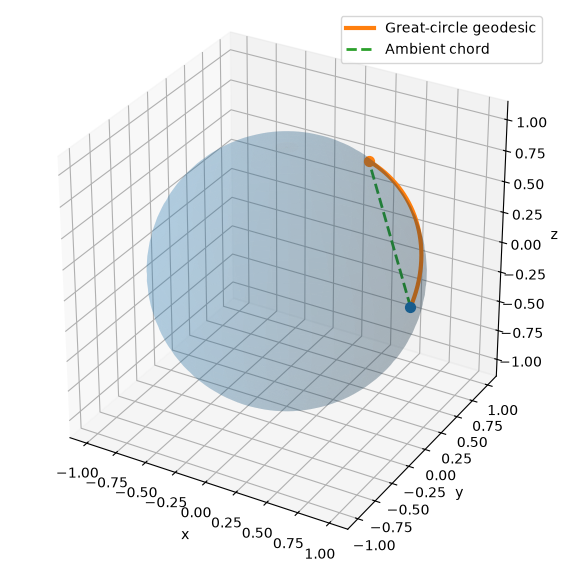

In [1]:
import numpy as np
import matplotlib.pyplot as plt

p = np.array([1.0, 0.0, 0.0])
q = np.array([0.25, 0.75, 0.6123724357])
q = q / np.linalg.norm(q)

theta = np.arccos(np.clip(p @ q, -1.0, 1.0))
t = np.linspace(0.0, 1.0, 200)
if theta < 1e-8:
    arc = (1 - t[:, None]) * p + t[:, None] * q
else:
    arc = (np.sin((1 - t) * theta)[:, None] / np.sin(theta) * p
           + np.sin(t * theta)[:, None] / np.sin(theta) * q)

u = np.linspace(0, 2 * np.pi, 80)
v = np.linspace(0, np.pi, 40)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(xs, ys, zs, alpha=0.18, linewidth=0)
ax.plot(arc[:, 0], arc[:, 1], arc[:, 2], linewidth=3,
        label="Great-circle geodesic")
ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], q[2]],
        linestyle="--", linewidth=2, label="Ambient chord")
ax.scatter(*p, s=50)
ax.scatter(*q, s=50)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))
ax.legend()
plt.show()

## 4. The exponential map

Fix $p\in\mathcal M$. Let $\gamma_v$ be the geodesic with initial data

$$
\gamma_v(0)=p,\qquad \dot\gamma_v(0)=v\in T_p\mathcal M.
$$

If this geodesic exists up to time $1$, define the **exponential map**

$$
\exp_p(v)=\gamma_v(1).
$$

Equivalently, $\exp_p(tv)=\gamma_v(t)$ whenever defined. Thus the exponential map turns an initial tangent vector into the point reached by following its geodesic.

It is generally defined only on a neighborhood of $0\in T_p\mathcal M$, though for a geodesically complete manifold it is defined on all of $T_p\mathcal M$.

### Euclidean example

In $\mathbb R^n$, $\gamma_v(t)=p+tv$, hence

$$
\exp_p(v)=p+v.
$$

### Sphere example

For the unit sphere, $p\in S^2$, $v\in T_pS^2$, and $v\ne0$,

$$
\exp_p(v)=\cos(\|v\|)\,p+
\frac{\sin(\|v\|)}{\|v\|}\,v,
$$

with $\exp_p(0)=p$. This follows the great circle launched from $p$ in direction $v$. Globally, the exponential map need not be injective: different tangent vectors may reach the same point.

## 5. Geodesic distance

The Riemannian distance between points $p,q$ is the infimum of lengths of piecewise-smooth curves joining them:

$$
d_g(p,q)=\inf_{\gamma:p\to q}L_g(\gamma).
$$

A curve realizing the infimum is a length-minimizing curve; when suitably parameterized, it is a minimizing geodesic. Geodesics are locally length-minimizing, but need not minimize length over every long interval.

In Euclidean space, $d_g(p,q)=\|p-q\|_2$. On the unit sphere,

$$
d_{S^2}(p,q)=\arccos(p^\mathsf Tq).
$$

This is the length of the shorter great-circle arc, not the length of the chord through ambient space.

## 6. Hopf–Rinow theorem

A Riemannian manifold is **geodesically complete** if every geodesic extends for all real parameter values. It is **complete as a metric space** if every Cauchy sequence under $d_g$ converges to a point of the manifold.

### Hopf–Rinow theorem — statement

Let $(\mathcal M,g)$ be a connected, finite-dimensional Riemannian manifold. The following are equivalent:

1. $(\mathcal M,d_g)$ is complete as a metric space.
2. $(\mathcal M,g)$ is geodesically complete.
3. For every $p\in\mathcal M$, $\exp_p$ is defined on all of $T_p\mathcal M$.
4. Every pair of points in $\mathcal M$ can be joined by a length-minimizing geodesic.

Moreover, every closed and bounded subset of $\mathcal M$ is compact.

The theorem does **not** say that every geodesic between two points is minimizing. It guarantees that at least one minimizing geodesic exists between each pair of points under these hypotheses. Completeness connects global metric behavior to the ability to extend geodesics and find shortest paths.

## 7. Nash embedding theorem

A Riemannian manifold is defined intrinsically; it need not initially be given as a subset of Euclidean space. The Nash embedding theorem says that it can nevertheless be represented in Euclidean space while preserving its metric.

### Nash embedding theorem — statement

For every smooth, finite-dimensional Riemannian manifold $(\mathcal M,g)$, there is a smooth isometric embedding into some sufficiently high-dimensional Euclidean space,

$$
\iota:(\mathcal M,g)\hookrightarrow\mathbb R^N,
$$

such that for all $p\in\mathcal M$ and $X,Y\in T_p\mathcal M$,

$$
g_p(X,Y)=\langle d\iota_p(X),d\iota_p(Y)\rangle_{\mathbb R^N}.
$$

The theorem has variants with different hypotheses and dimension bounds; this is the broad smooth Riemannian statement relevant here.

An isometric embedding preserves curve lengths and the induced Riemannian distance. It does not generally send geodesics to straight lines in the ambient space, and it is not unique. Nor does the theorem imply that an arbitrary embedding preserves the metric.

## 8. Intrinsic geometry, embeddings, and isometries

A quantity is **intrinsic** if it is determined by the Riemannian metric, without choosing a particular ambient embedding. Curve lengths, geodesic distances, and metric angles are intrinsic.

An **isometry** between $(\mathcal M,g)$ and $(\mathcal N,h)$ is a diffeomorphism $\varphi:\mathcal M\to\mathcal N$ satisfying

$$
h_{\varphi(p)}(d\varphi_pX,d\varphi_pY)=g_p(X,Y).
$$

Isometries preserve metric pairings, lengths of curves, and geodesic distances.

A surface may bend in ambient space while preserving its intrinsic distances. For example, a cylinder can locally be unrolled onto a plane without stretching; the cylinder and plane are locally isometric. The cylinder looks curved in $\mathbb R^3$, but its Gaussian curvature is zero. This illustrates the distinction between intrinsic geometry and appearance in an ambient space.

Intrinsic and extrinsic representations are both useful. Intrinsic information can be appropriate when predictions should be unchanged by isometric bending. Extrinsic coordinates may be essential when ambient orientation, position, or shape is relevant to the task.

## 9. Connection with Geometric Deep Learning

These are conceptual connections to GDL, building on the geometry above.

### 9.1 Signals on manifolds

A scalar signal on a manifold is a function

$$
f:\mathcal M\to\mathbb R.
$$

Examples include temperature over a surface, a scalar field on a mesh, or a learned feature attached to each surface point. Vector-valued features in tangent spaces require additional care: they are not interchangeable with ordinary vectors in a fixed $\mathbb R^k$.

### 9.2 Intrinsic methods and deformation robustness

A method that depends only on intrinsic quantities is unchanged by an isometry. For example, geodesic distances are preserved under isometries. This gives a principled route to models insensitive to bending that preserves the metric.

This is not invariance to arbitrary deformations: stretching can change the metric and therefore alter geodesic distances.

### 9.3 The metric as inductive bias

The Riemannian metric determines lengths, angles, geodesics, and metric-dependent differential operators. These structures can inform models operating on curved domains. The appropriate choice between intrinsic and extrinsic information depends on the task's symmetries and physical meaning.

Fourier analysis on manifolds and Laplace-type operators build on this foundation; they are deliberately excluded here for a separate notebook.

## 10. Worked conceptual comparisons

### A. Chord versus arc

For unit vectors $p,q\in S^2$, the ambient chord length is

$$
\|p-q\|_2=\sqrt{2-2p^\mathsf Tq},
$$

while the spherical geodesic distance is

$$
d_{S^2}(p,q)=\arccos(p^\mathsf Tq).
$$

The chord is shorter than the surface arc except in the limiting case where the points coincide. For nearby points, the two lengths are close.

### B. Local versus global behavior

The exponential map behaves regularly near the zero vector in $T_p\mathcal M$, but it need not be globally injective. On a sphere, infinitely many great-circle semicircles join a point to its antipode. This is compatible with geodesics being locally length-minimizing.

### C. Intrinsic versus extrinsic

Geodesic distance is intrinsic. Ambient coordinates and the visual appearance of a particular embedding are extrinsic. An isometric bending can change the latter while preserving the former.

## 11. Exercises

These are original exercises based on the topics in this notebook, not verbatim reproductions of textbook problems.

1. **Metric matrix.** Let $G=\begin{pmatrix}2&1\\1&3\end{pmatrix}$. Verify that $G$ is positive definite and compute the metric norm of $v=(1,-1)^\mathsf T$.
2. **Curve length.** For $\gamma(t)=(a\cos t,a\sin t)$, $t\in[0,\theta]$, compute its Euclidean length and interpret it geometrically.
3. **Sphere tangent space.** Differentiate $p^\mathsf Tp=1$ to show that $T_pS^2=\{v:p^\mathsf Tv=0\}$.
4. **Geodesic distance.** Explain why the spherical distance between unit vectors $p,q$ is their angle. Compare it with the chord length.
5. **Exponential map.** Verify that the sphere formula for $\exp_p(v)$ lies on $S^2$, using $p^\mathsf Tp=1$ and $p^\mathsf Tv=0$.
6. **Hopf–Rinow.** Explain the difference between geodesic completeness and every geodesic being globally minimizing. Which property is equivalent to metric completeness?
7. **Nash embedding.** Explain what it means for an embedding to be isometric. Why need not an arbitrary smooth embedding preserve the metric?
8. **Intrinsic versus extrinsic.** Give one example of each and explain your choices.
9. **GDL design.** If predictions should be invariant under isometric bending, what information could be used? Which coordinate choices might introduce unwanted embedding dependence?
10. **Non-minimizing geodesic.** Give an example of a geodesic that is not globally minimizing over a long interval, and explain why this does not contradict its local property.

## 12. Summary

A Riemannian metric equips every tangent space with a smoothly varying inner product. It defines tangent-vector norms, curve lengths, and geodesic distance. Geodesics generalize straight lines, while the exponential map records where a geodesic travels from a specified initial tangent vector.

The **Hopf–Rinow theorem** connects metric completeness, geodesic completeness, and existence of minimizing geodesics. The **Nash embedding theorem** guarantees an isometric embedding into a sufficiently high-dimensional Euclidean space. Together, these results clarify the relationship between intrinsic geometry and ambient representations.

For GDL, the key lesson is that geometric structure can be built into a model: intrinsic quantities respect isometries, whereas ambient-coordinate methods may depend on how data are embedded. The appropriate choice depends on the task.

## References

- M. M. Bronstein, J. Bruna, T. Cohen, and P. Veličković, **Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges**, Section 4.4, [arXiv:2104.13478](https://arxiv.org/abs/2104.13478). This notebook stops before “Fourier Analysis on Manifolds.”
- H. Sáez de Ocáriz Borde and M. Bronstein, **Mathematical Foundations of Geometric Deep Learning**, [arXiv:2508.02723](https://arxiv.org/abs/2508.02723).
- L. W. Tu, **Differential Geometry: Connections, Curvature, and Characteristic Classes**.